<a href="https://colab.research.google.com/github/atharavmankotia08/AMARSUHAGJEWELLERS/blob/master/AI_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, multilabel_confusion_matrix
)

In [11]:
# ==========================================
# FEATURE FUNCTIONS
# ==========================================

def search_movie(df):
    movie_name = input("Enter a movie name (partial or full): ")
    result = df[df["Series_Title"].str.contains(movie_name, case=False, na=False)]

    if len(result) > 0:
        print(f"\nFound {len(result)} matching movie(s):\n")
        for idx, row in result.iterrows():
            print(f"Title: {row['Series_Title']}")
            print(f"Genre: {row['Genre']}")
            print("-" * 20)
    else:
        print("No matching movies found in the CSV.")

def compare_movies(df):
    movie1 = input("Enter the first movie: ")
    movie2 = input("Enter the second movie: ")

    matches1 = df[df["Series_Title"].str.contains(movie1, case=False, na=False)]
    matches2 = df[df["Series_Title"].str.contains(movie2, case=False, na=False)]

    if len(matches1) > 0 and len(matches2) > 0:
        film1 = matches1.iloc[0]
        film2 = matches2.iloc[0]

        genres1 = set(str(film1["Genre"]).split(", "))
        genres2 = set(str(film2["Genre"]).split(", "))

        print(f"\nSelected '{film1['Series_Title']}' and '{film2['Series_Title']}'.\n")
        print(f"{film1['Series_Title']} genres:", genres1)
        print(f"{film2['Series_Title']} genres:", genres2)
        print("Genres they share:", genres1.intersection(genres2))
        print("-" * 40)

        rating1 = float(film1["IMDB_Rating"])
        rating2 = float(film2["IMDB_Rating"])
        print(f"{film1['Series_Title']} IMDB Rating: {rating1}")
        print(f"{film2['Series_Title']} IMDB Rating: {rating2}")

        if rating1 > rating2:
            print(f"👉 '{film1['Series_Title']}' is rated higher by {round(rating1 - rating2, 1)} points.")
        elif rating2 > rating1:
            print(f"👉 '{film2['Series_Title']}' is rated higher by {round(rating2 - rating1, 1)} points.")
        else:
            print("👉 Both movies have the same IMDB rating!")
    else:
        if len(matches1) == 0:
            print(f"Could not find any matches for: '{movie1}'")
        if len(matches2) == 0:
            print(f"Could not find any matches for: '{movie2}'")

def mood_recommendations(df):
    mood = input("How are you feeling? (happy, sad, excited, scared): ")
    mood_genres = {
        "happy": ["Comedy", "Family", "Animation"],
        "sad": ["Drama", "Romance"],
        "excited": ["Action", "Adventure", "Thriller"],
        "scared": ["Horror", "Thriller"]
    }

    if mood.lower() in mood_genres:
        wanted_genres = mood_genres[mood.lower()]
        suggestions = df[
            df["Genre"].astype(str).str.contains("|".join(wanted_genres), case=False, na=False)
        ]
        print(f"\nMovie suggestions for feeling '{mood}':")
        sample_size = min(10, len(suggestions))
        random_suggestions = suggestions.sample(n=sample_size)
        print(random_suggestions[["Series_Title", "Genre", "IMDB_Rating"]].to_string(index=False))
    else:
        print("Mood not found. Try happy, sad, excited, or scared.")

def search_by_genre(df):
    genre_name = input("Enter a genre (e.g., Comedy, Action, Drama): ")
    genre_movies = df[df["Genre"].astype(str).str.contains(genre_name, case=False, na=False)]

    print(f"\nMovies in the '{genre_name}' genre:")
    if len(genre_movies) > 0:
        sample_size = min(10, len(genre_movies))
        random_genre_movies = genre_movies.sample(n=sample_size)
        print(random_genre_movies[["Series_Title", "Genre", "IMDB_Rating"]].to_string(index=False))
    else:
        print(f"No movies found matching the genre: {genre_name}")

def search_by_year(df):
    year = input("Enter a release year: ")
    year_movies = df[df["Released_Year"].astype(str) == year]

    if len(year_movies) > 0:
        print(f"\nMovies released in {year}:")
        print(year_movies[["Series_Title", "Genre"]].head(20).to_string(index=False))
    else:
        print(f"No movies found for the year: {year}")

def movie_overview(df):
    movie_overview_name = input("Enter a movie name for overview: ")
    movie_result = df[df["Series_Title"].astype(str).str.lower() == movie_overview_name.lower()]

    if len(movie_result) > 0:
        overview = movie_result.iloc[0].get("Overview", "No overview available.")
        print(f"\nOverview for {movie_result.iloc[0]['Series_Title']}:")
        print(overview)
    else:
        print("Movie not found in the CSV.")

def plot_genre_distribution(df):
    genre_counts = {}
    for genre_list in df["Genre"].dropna():
        for genre in str(genre_list).split(", "):
            genre = genre.strip()
            genre_counts[genre] = genre_counts.get(genre, 0) + 1

    genre_df = pd.DataFrame(list(genre_counts.items()), columns=["Genre", "Number of Movies"])

    plt.figure(figsize=(10, 5))
    sns.barplot(data=genre_df, x="Number of Movies", y="Genre", color="teal")
    plt.title("Number of Movies in Each Genre")
    plt.tight_layout()
    plt.show()

def run_ml_models(df):
    print("\nRunning Machine Learning Pipeline...")
    ml_data = df.dropna(subset=["Series_Title", "Genre"]).copy()
    ml_data["genre_list"] = ml_data["Genre"].astype(str).apply(
        lambda value: [genre.strip() for genre in value.split(",")]
    )

    X_text = ml_data["Series_Title"].astype(str)
    mlb = MultiLabelBinarizer()
    Y = mlb.fit_transform(ml_data["genre_list"])

    X_train, X_test, Y_train, Y_test = train_test_split(
        X_text, Y, test_size=0.2, random_state=42
    )

    vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), max_features=1000)
    X_train_numbers = vectorizer.fit_transform(X_train)
    X_test_numbers = vectorizer.transform(X_test)

    models = {
        "Baseline": OneVsRestClassifier(DummyClassifier(strategy="most_frequent")),
        "Logistic Regression": OneVsRestClassifier(LogisticRegression(max_iter=1000)),
        "Linear SVC": OneVsRestClassifier(LinearSVC())
    }

    results = []
    trained_models = {}

    for name, model in models.items():
        model.fit(X_train_numbers, Y_train)
        predictions = model.predict(X_test_numbers)
        trained_models[name] = model

        results.append({
            "Model": name,
            "Accuracy (%)": accuracy_score(Y_test, predictions) * 100,
            "Precision (%)": precision_score(Y_test, predictions, average="micro", zero_division=0) * 100,
            "Recall (%)": recall_score(Y_test, predictions, average="micro", zero_division=0) * 100,
            "F1-score (%)": f1_score(Y_test, predictions, average="micro", zero_division=0) * 100
        })

    results_df = pd.DataFrame(results).sort_values("F1-score (%)", ascending=False).reset_index(drop=True)
    print("\nModel Performance Comparison:")
    display(results_df.round(2))

    # Best Model Evaluation
    best_model_name = results_df.iloc[0]["Model"]
    best_model = trained_models[best_model_name]
    best_predictions = best_model.predict(X_test_numbers)

    genre_matrices = multilabel_confusion_matrix(Y_test, best_predictions)
    overall_matrix = genre_matrices.sum(axis=0)

    print(f"\nBest Model: {best_model_name}")
    print("Overall Confusion Matrix:")
    print(overall_matrix)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        overall_matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted No", "Predicted Yes"],
        yticklabels=["Actual No", "Actual Yes"]
    )
    plt.title(f"Combined Confusion Matrix ({best_model_name})")
    plt.xlabel("Prediction")
    plt.ylabel("Actual value")
    plt.tight_layout()
    plt.show()

# ==========================================
# MAIN INTERACTIVE MENU LOOP
# ==========================================
def main():
    print("Loading dataset...")
    df = pd.read_csv('/content/imdb_top_1000.csv')
    if 'Poster_Link' in df.columns:
        df = df.drop(columns=['Poster_Link'])
    print("Dataset Loaded Successfully!\n")

    while True:
        print("\n==============================")
        print("   IMDB MOVIE UTILITY MENU    ")
        print("==============================")
        print("1. Search Movie by Name")
        print("2. Compare Two Movies")
        print("3. Mood-Based Recommendations")
        print("4. Search Movies by Genre")
        print("5. Search Movies by Release Year")
        print("6. Get Movie Overview")
        print("7. Plot Genre Distribution Chart")
        print("8. Run Machine Learning Models & Evaluation")
        print("9. Exit")

        choice = input("\nSelect a feature to test (1-9): ").strip()

        if choice == '1':
            search_movie(df)
        elif choice == '2':
            compare_movies(df)
        elif choice == '3':
            mood_recommendations(df)
        elif choice == '4':
            search_by_genre(df)
        elif choice == '5':
            search_by_year(df)
        elif choice == '6':
            movie_overview(df)
        elif choice == '7':
            plot_genre_distribution(df)
        elif choice == '8':
            run_ml_models(df)
        elif choice == '9':
            print("Exiting program. Have a great day!")
            break
        else:
            print("❌ Invalid choice. Please enter a number between 1 and 9.")

# Run the program
if __name__ == "__main__":
    main()

Loading dataset...
Dataset Loaded Successfully!


   IMDB MOVIE UTILITY MENU    
1. Search Movie by Name
2. Compare Two Movies
3. Mood-Based Recommendations
4. Search Movies by Genre
5. Search Movies by Release Year
6. Get Movie Overview
7. Plot Genre Distribution Chart
8. Run Machine Learning Models & Evaluation
9. Exit

Select a feature to test (1-9): 9
Exiting program. Have a great day!


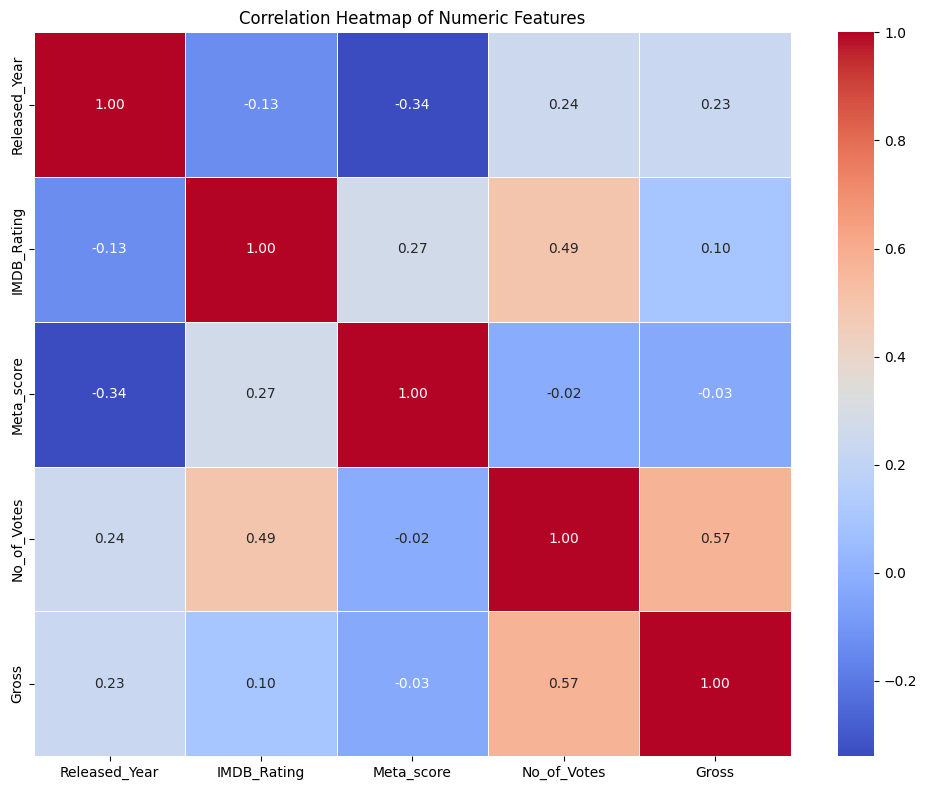

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('/content/imdb_top_1000.csv')

# Clean and convert numeric columns that might be read as string
if 'Gross' in df.columns:
    df['Gross'] = df['Gross'].str.replace(',', '').astype(float)
if 'Released_Year' in df.columns:
    df['Released_Year'] = pd.to_numeric(df['Released_Year'], errors='coerce')

# Filter only numerical columns for correlation mapping
numeric_cols = df.select_dtypes(include=['float64', 'int64'])

# Calculate correlation matrix
corr_matrix = numeric_cols.corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()

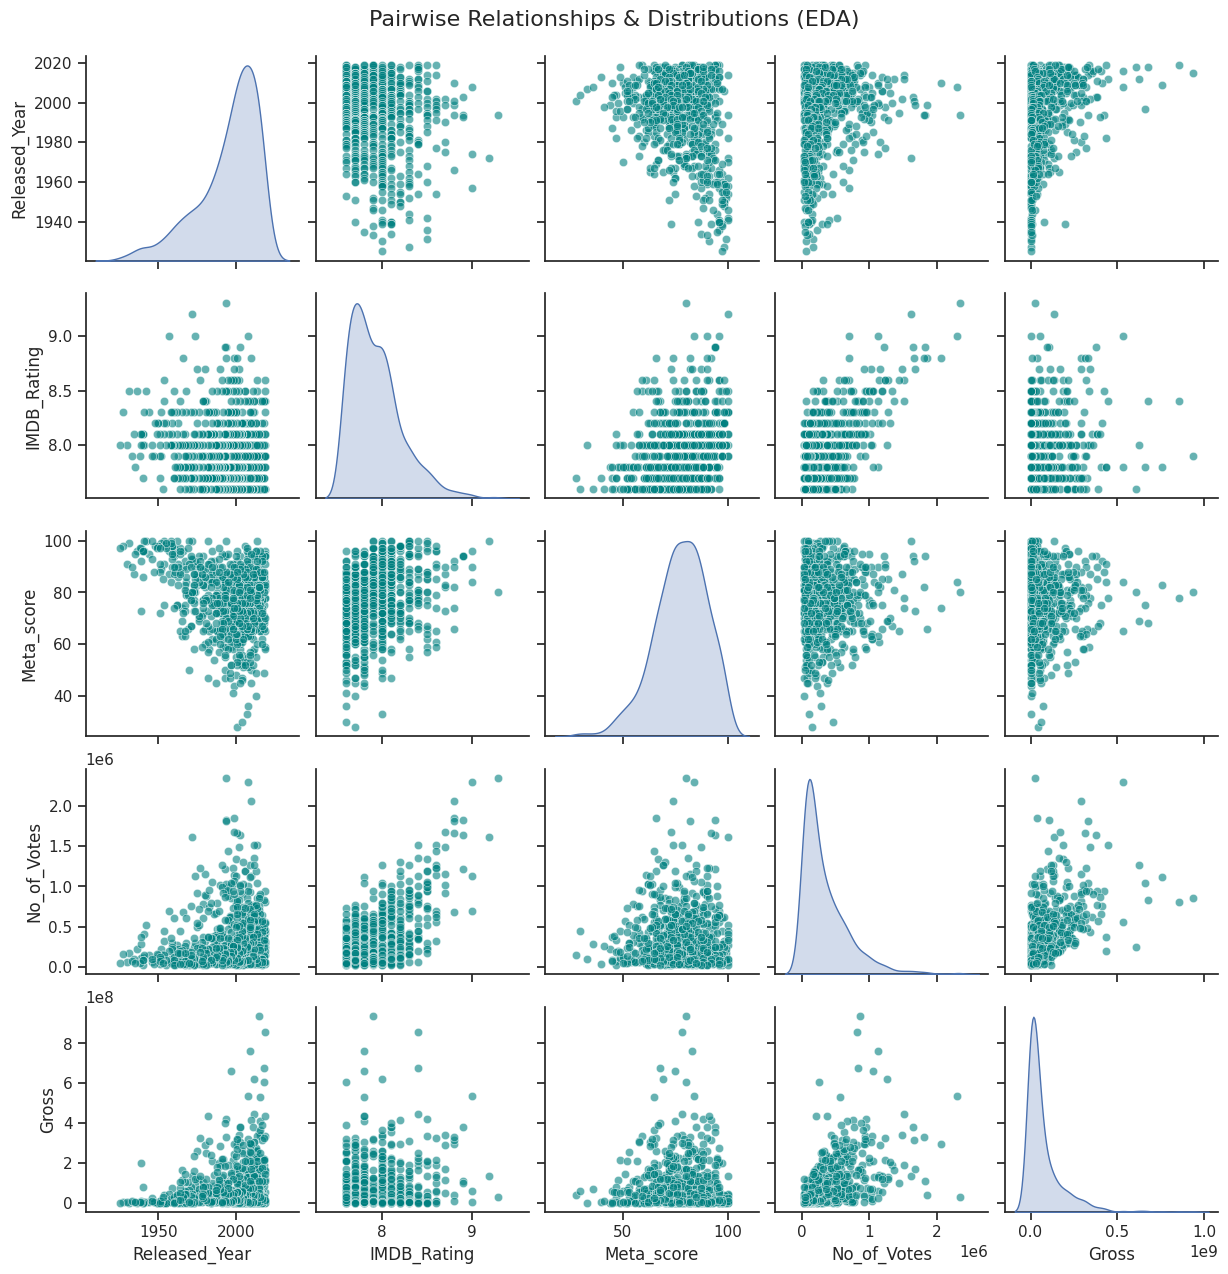

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure dataset is loaded and numerical columns are cleaned
df = pd.read_csv('/content/imdb_top_1000.csv')
if 'Gross' in df.columns:
    df['Gross'] = df['Gross'].str.replace(',', '').astype(float)
if 'Released_Year' in df.columns:
    df['Released_Year'] = pd.to_numeric(df['Released_Year'], errors='coerce')

numeric_cols = df.select_dtypes(include=['float64', 'int64']).dropna()

# Create a pair plot to visualize distributions and relationships
sns.set_theme(style="ticks")
g = sns.pairplot(numeric_cols, diag_kind='kde', plot_kws={'alpha': 0.6, 'color': 'teal'})
g.fig.suptitle('Pairwise Relationships & Distributions (EDA)', y=1.02, fontsize=16)
plt.show()